Sobel 算子实现滤波

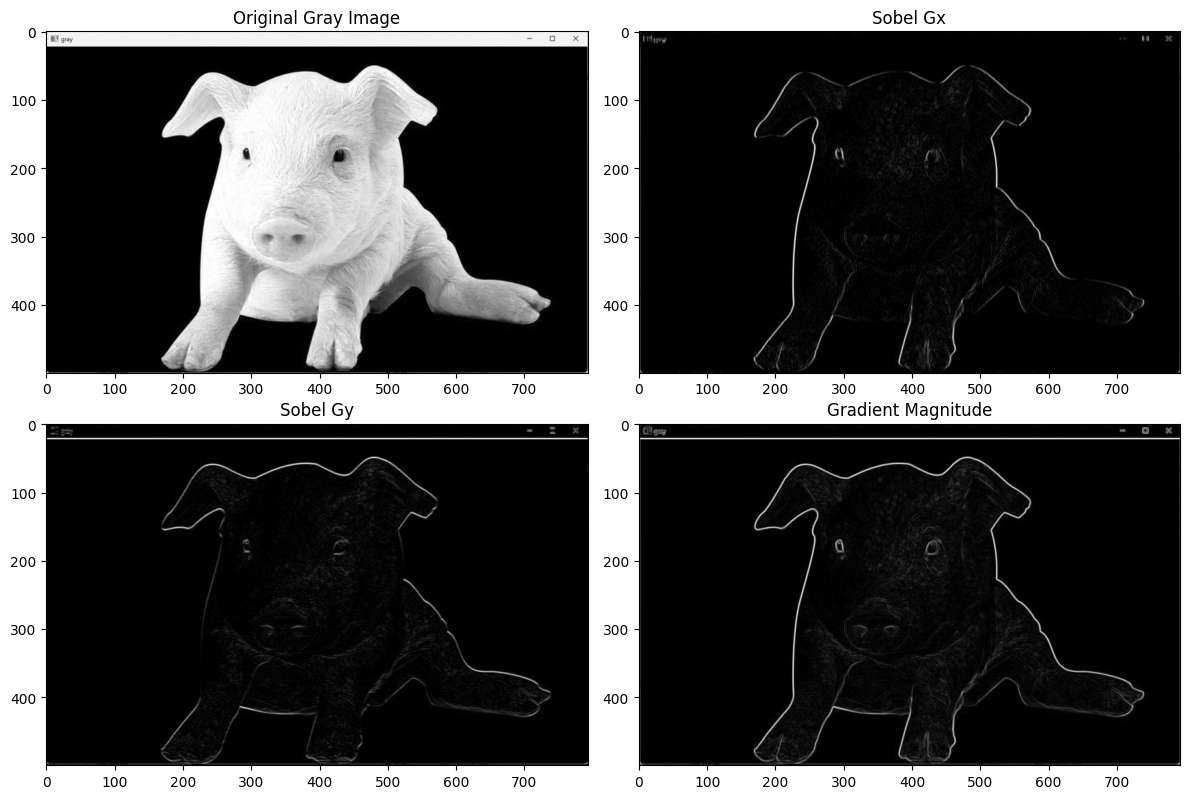

In [ ]:
'''
Sobel算子的图像滤波,以及结果展示.
'''

import cv2
import numpy as np
import matplotlib.pyplot as plt


pig = cv2.imread("pig.jpg")

if pig is None:
    print("没有找到图像")
    raise FileNotFoundError("没有图像")


img = cv2.cvtColor(pig, cv2.COLOR_BGR2GRAY)
#pig.jpg是已经处理好的灰度图了

#水平与垂直梯度
Gx = cv2.Sobel(img, 
                cv2.CV_64F, 
                1,0, 
                ksize=3)
Gy = cv2.Sobel(img, 
                cv2.CV_64F,
                0,1,
                ksize=3)


magnitude =np.sqrt(Gx**2+Gy**2)

#归一化处理
magnitude = cv2.normalize(
    magnitude,
    None,
    0, 255,
    cv2.NORM_MINMAX
).astype(np.uint8)

# 计算梯度方向
angle = np.arctan2(Gy, Gx)


plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Gray Image")

#x 方向
plt.subplot(2, 2, 2)
plt.imshow(np.abs(Gx), cmap="gray")
plt.title("Sobel Gx")

#y 方向
plt.subplot(2, 2, 3)
plt.imshow(np.abs(Gy), cmap="gray")
plt.title("Sobel Gy")

#均一化后结果
plt.subplot(2, 2, 4)
plt.imshow(magnitude, cmap="gray")
plt.title("Gradient Magnitude")

plt.tight_layout()
plt.show()




Canny 边缘检测算法：
流程1.高斯滤波——>梯度计算————>非极大值抑制————>双阈值检测与边缘链接————>wanchenng

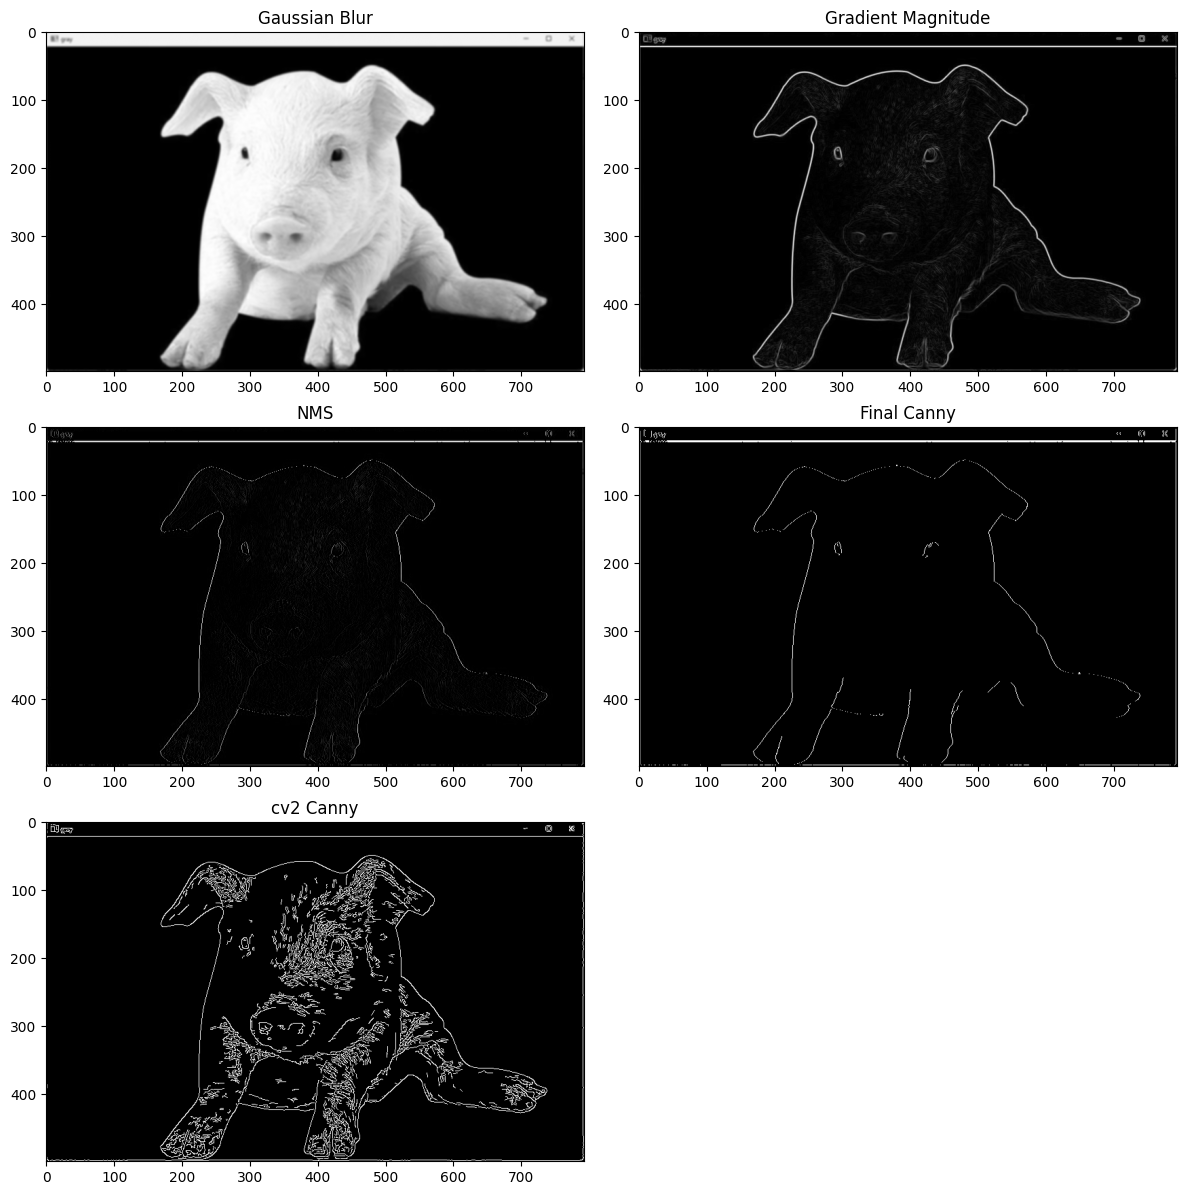

In [14]:
blur= cv2.GaussianBlur(img,
                       (5,5),
                       sigmaX=1.4)


#计算同上
Gx = cv2.Sobel(img, 
                cv2.CV_64F, 
                1,0, 
                ksize=3)
Gy = cv2.Sobel(img, 
                cv2.CV_64F,
                0,1,
                ksize=3)


magnitude =np.sqrt(Gx**2+Gy**2)

#归一化处理
magnitude = cv2.normalize(
    magnitude,
    None,
    0, 255,
    cv2.NORM_MINMAX
).astype(np.uint8)

angle = np.arctan2(Gy, Gx)
angle= (angle + 180)%180


#非极大值抑制
def nms(magnitude, angle):

    h, w = magnitude.shape

    result = np.zeros(
        (h, w),
        dtype=np.float64
    )

    # 遍历图像内部
    for i in range(1, h - 1):
        for j in range(1, w - 1):

            direction = angle[i, j]

            current = magnitude[i, j]

            # 根据角度选择比较方向
            if (0 <= direction < 22.5 or
                157.5 <= direction < 180):

                before = magnitude[i, j - 1]
                after = magnitude[i, j + 1]

            elif 22.5 <= direction < 67.5:

                before = magnitude[i - 1, j + 1]
                after = magnitude[i + 1, j - 1]

            elif 67.5 <= direction < 112.5:

                before = magnitude[i - 1, j]
                after = magnitude[i + 1, j]

            else:

                before = magnitude[i - 1, j - 1]
                after = magnitude[i + 1, j + 1]

            # 判断当前像素是否为局部最大值
            if current >= before and current >= after:

                result[i, j] = current

    return result

#双阈值检测与边缘链接
def double_threshold(nms, low_threshold, high_threshold):

    h, w = nms.shape

    # 0：非边缘
    # 1：弱边缘
    # 2：强边缘

    result = np.zeros(
        (h, w),
        dtype=np.uint8
    )

    weak = 1
    strong = 2

    # 双阈值分类
    result[nms >= high_threshold] = strong

    result[
        (nms >= low_threshold) &
        (nms < high_threshold)
    ] = weak

    # 边缘连接
    # 不断寻找与强边缘相邻的弱边缘
    while True:

        previous = result.copy()

        for i in range(1, h - 1):
            for j in range(1, w - 1):

                if result[i, j] == weak:

                    neighborhood = result[
                        i-1:i+2,
                        j-1:j+2
                    ]

                    if np.any(neighborhood == strong):
                        result[i, j] = strong

        # 如果没有新的边缘被连接，则结束
        if np.array_equal(previous, result):
            break

    # 最终只保留强边缘
    result[result != strong] = 0
    result[result == strong] = 255

    return result


#后续实现：
nms_result=nms(magnitude,angle)
edge=double_threshold(nms_result,low_threshold=40,high_threshold=100)

#对比cv2
cv2_Canny=cv2.Canny(img,
                    50,100,
                    apertureSize=3,
                    L2gradient=True)
plt.figure(figsize=(12, 12))

plt.subplot(3, 2, 1)
plt.imshow(blur, cmap="gray")
plt.title("Gaussian Blur")

plt.subplot(3, 2, 2)
plt.imshow(magnitude, cmap="gray")
plt.title("Gradient Magnitude")

plt.subplot(3, 2, 3)
plt.imshow(nms_result, cmap="gray")
plt.title("NMS")

plt.subplot(3, 2, 4)
plt.imshow(edge, cmap="gray")
plt.title("Final Canny")

plt.subplot(3, 2, 5)
plt.imshow(cv2_Canny, cmap="gray")
plt.title("cv2 Canny")

plt.tight_layout()
plt.show()

Hardris 角点检测算法

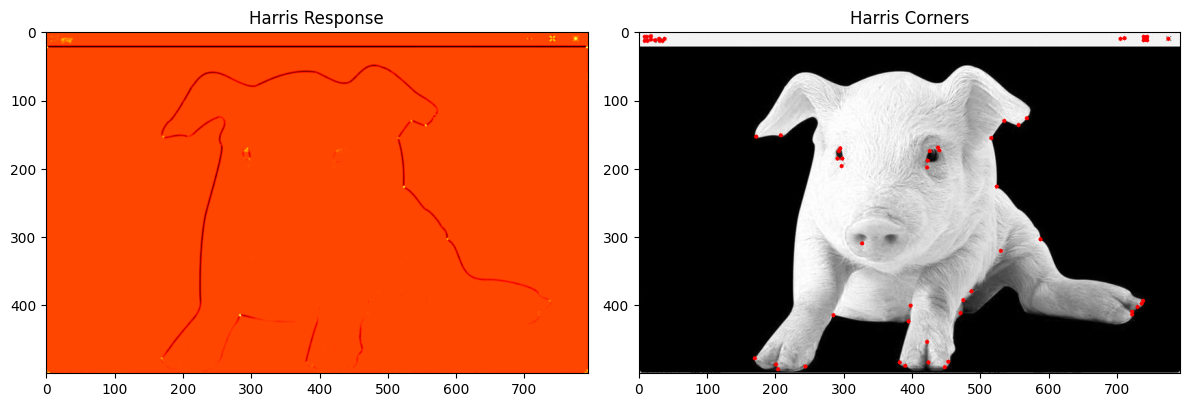

In [16]:
#梯度计算，矩阵以及高斯滤波

Ix = cv2.Sobel(
    img,
    cv2.CV_64F,
    1, 0,
    ksize=3
)

Iy = cv2.Sobel(
    img,
    cv2.CV_64F,
    0, 1,
    ksize=3
)

Ix2 = Ix ** 2
Iy2 = Iy ** 2
Ixy = Ix * Iy

Sxx = cv2.GaussianBlur(
    Ix2, (5, 5), 1
)

Syy = cv2.GaussianBlur(
    Iy2, (5, 5), 1
)

Sxy = cv2.GaussianBlur(
    Ixy, (5, 5), 1
)


#计算响应值
alpha = 0.04
det_M = Sxx * Syy - Sxy ** 2
trace_M = Sxx + Syy
R = det_M - alpha * trace_M ** 2



#计算阈值
threshold= 0.01*R.max()
candidate=R>threshold

#局部最大值
def harris_nms(R, threshold, window_size=5):

    h, w = R.shape

    result = np.zeros(
        (h, w),
        dtype=np.uint8
    )

    pad = window_size // 2

    for i in range(pad, h - pad):
        for j in range(pad, w - pad):

            if R[i, j] > threshold:

                window = R[
                    i-pad:i+pad+1,
                    j-pad:j+pad+1
                ]

                if R[i, j] == np.max(window):
                    result[i, j] = 255

    return result

corners=harris_nms(R, threshold=0.01*R.max(),window_size=5)

result = cv2.cvtColor(
    img,
    cv2.COLOR_GRAY2BGR
)

# 绘制角点
y, x = np.where(corners > 0)

for px, py in zip(x, y):

    cv2.circle(
        result,
        (px, py),
        3,
        (0, 0, 255),
        -1
    )

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(R, cmap="hot")
plt.title("Harris Response")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(
    result,
    cv2.COLOR_BGR2RGB
))
plt.title("Harris Corners")

plt.tight_layout()
plt.show()

直方图均值化

/tmp/ipykernel_14823/2679560249.py:36: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(img.ravel(), 256, [0, 256])
/tmp/ipykernel_14823/2679560249.py:44: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(equalized.ravel(), 256, [0, 256])


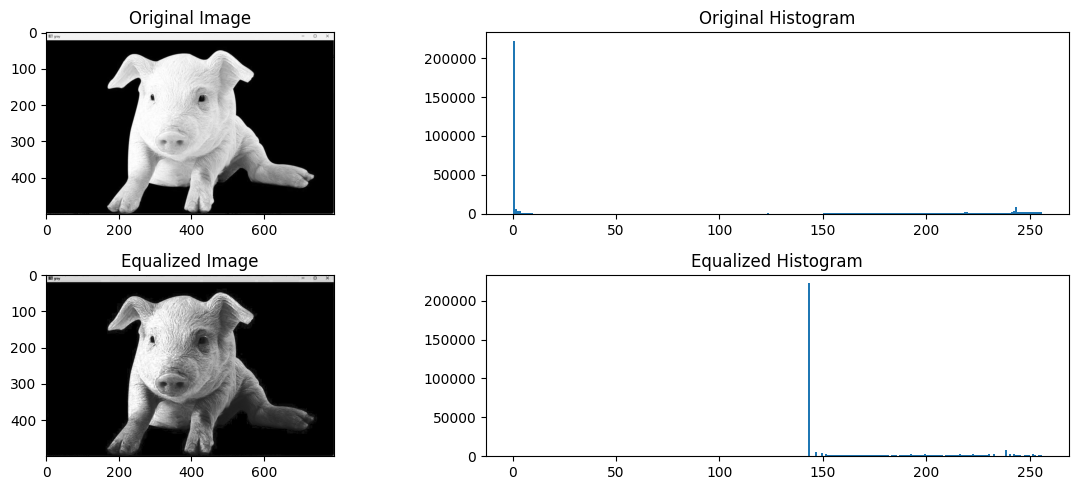

In [18]:
def my_hist_equalization(gray):

    #统计灰度直方图
    hist = np.bincount(
        gray.ravel(),
        minlength=256
    )

    #计算灰度概率
    total_pixels = gray.size
    probability = hist / total_pixels

#计算累积分布函数
    cdf = np.cumsum(probability)

    #计算灰度映射表
    mapping = np.round(
        cdf * 255
    ).astype(np.uint8)

    #根据映射表生成新图像
    result = mapping[gray]

    return result


equalized = my_hist_equalization(img)

plt.figure(figsize=(12, 5))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")

plt.subplot(2, 2, 2)
plt.hist(img.ravel(), 256, [0, 256])
plt.title("Original Histogram")

plt.subplot(2, 2, 3)
plt.imshow(equalized, cmap="gray")
plt.title("Equalized Image")

plt.subplot(2, 2, 4)
plt.hist(equalized.ravel(), 256, [0, 256])
plt.title("Equalized Histogram")

plt.tight_layout()
plt.show()